# **Baseline models**

1. Ridge regression;
2. histogram gradient boosting;
3. Neural Network (light/basic)

In [1]:
from pathlib import Path
import hashlib
import random
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

random_state = 42

train_percentage = 0.60
val_percentage = 0.10
calib_percentage = 0.15
test_percentage = 0.15

EXPECTED_LABELLED_PLANETS = 41423
EXPECTED_SPECTRAL_CHANNELS = 52
EXPECTED_FEATURE_COUNT = 111
EXPECTED_SPLIT_COUNTS = {
    "train": 24853,
    "validation": 4142,
    "calibration": 6214,
    "test": 6214
}

EXPECTED_SPLIT_SHA256 = (
    "6b3587361b009d0cd5b0be439d665d367"
    "9c3cf4f767ff35ce44496462ec15a74"
)

SPECTRUM_FEATURES = [
    f"spectrum_{channel:02d}" for channel in range(EXPECTED_SPECTRAL_CHANNELS)
    ]

NOISE_FEATURES = [
    f"noise_{channel:02d}" for channel in range(EXPECTED_SPECTRAL_CHANNELS)
    ]

METADATA_FEATURES = [
    "star_distance",
    "star_mass_kg",
    "star_radius_m",
    "star_temperature",
    "planet_mass_kg",
    "planet_orbital_period",
    "planet_distance",
]

TARGET_COLUMNS = [
    "planet_radius",
    "planet_temp",
    "log_H2O",
    "log_CO2",
    "log_CO",
    "log_CH4",
    "log_NH3",
]

FEATURE_COLUMNS = [
    *SPECTRUM_FEATURES,
    *NOISE_FEATURES,
    *METADATA_FEATURES,
]

SPECTRAL_PATH = (
    PROJECT_ROOT
    / "FullDataset"
    / "TrainingData"
    / "SpectralData.hdf5"
)

AUXILIARY_PATH = (
    PROJECT_ROOT
    / "FullDataset"
    / "TrainingData"
    / "AuxillaryTable.csv"
)

TARGET_PATH = (
    PROJECT_ROOT
    / "FullDataset"
    / "TrainingData"
    / "Ground Truth Package"
    / "FM_Parameter_Table.csv"
)

SPLIT_ASSIGNMENT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "split_assignments_data.csv"
)

if len(FEATURE_COLUMNS) != EXPECTED_FEATURE_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_FEATURE_COUNT} features, "
        f"defined {len(FEATURE_COLUMNS)}."
    )

for required_path in [
    SPECTRAL_PATH,
    AUXILIARY_PATH,
    TARGET_PATH,
]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Required source file not found: {required_path}")

print("Project root:", PROJECT_ROOT)
print("Feature count:", len(FEATURE_COLUMNS))
print("Target count:", len(TARGET_COLUMNS))

Project root: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction
Feature count: 111
Target count: 7


### **Load the data**

In [3]:
metadata_source = pd.read_csv(AUXILIARY_PATH, dtype={"planet_ID": "string"})

target_source = pd.read_csv(TARGET_PATH, dtype={"planet_ID": "string"})


def validate_identifier_table(table: pd.DataFrame, source_name: str, required_columns: list[str]) -> None:
    missing_columns = [column for column in required_columns if column not in table.columns]

    if missing_columns:
        raise ValueError(f"{source_name} is missing columns: {missing_columns}")

    if table["planet_ID"].isna().any():
        raise ValueError(f"{source_name} has missing planet IDs.")

    if table["planet_ID"].duplicated().any():
        raise ValueError(f"{source_name} has duplicate planet IDs.")


validate_identifier_table(metadata_source, "Auxiliary metadata", ["planet_ID", *METADATA_FEATURES])

validate_identifier_table(target_source, "Target table", ["planet_ID", *TARGET_COLUMNS])

labelled_table = metadata_source[["planet_ID", *METADATA_FEATURES]].merge(
    target_source[["planet_ID", *TARGET_COLUMNS]],
    on="planet_ID",
    how="outer",
    validate="one_to_one",
    indicator=True
)

unmatched_mask = labelled_table["_merge"].ne("both")

if unmatched_mask.any():
    unmatched_examples = labelled_table.loc[unmatched_mask, ["planet_ID", "_merge"]].head()

    raise ValueError("Metadata and targets do not contain identical IDs: "f"{unmatched_examples}")

labelled_table = (
    labelled_table
    .drop(columns="_merge")
    .sort_values("planet_ID", kind="stable")
    .reset_index(drop=True)
)

if len(labelled_table) != EXPECTED_LABELLED_PLANETS:
    raise ValueError(f"Expected {EXPECTED_LABELLED_PLANETS} planets, found {len(labelled_table)}")

if not labelled_table["planet_ID"].is_unique:
    raise ValueError("Aligned planet IDs are not unique.")

print("Aligned labelled rows:", len(labelled_table))
print("Unique planet IDs:", labelled_table["planet_ID"].nunique())

Aligned labelled rows: 41423
Unique planet IDs: 41423


### **Split the data**

In [4]:
def split_assignment_hash(assignments: pd.DataFrame) -> str:
    """Return a fingerprint of the table."""
    csv_text = assignments[["planet_ID", "split"]].to_csv(index=False, lineterminator="\n")
    return hashlib.sha256(csv_text.encode("utf-8")).hexdigest()


def regenerate_split_assignments(ordered_planet_ids: np.ndarray) -> pd.DataFrame:
    """Reproduce exactly the splitting from notebook 03."""
    train_ids, remaining_ids = train_test_split(
        ordered_planet_ids,
        train_size= train_percentage,
        random_state=random_state,
        shuffle=True)

    remaining = 1.0 - train_percentage
    val_share = (val_percentage / remaining)

    

    validation_ids, calibration_and_test_ids = train_test_split(
        remaining_ids,
        train_size=val_percentage,
        random_state=random_state,
        shuffle=True
    )
    calib_share = (calib_percentage / (calib_percentage + test_percentage))

    calibration_ids, test_ids = train_test_split(
        calibration_and_test_ids,
        train_size=calib_share,
        random_state=random_state,
        shuffle=True
    )

    split_ids = {
        "train": train_ids,
        "validation": validation_ids,
        "calibration": calibration_ids,
        "test": test_ids,
    }

    return pd.concat([pd.DataFrame({"planet_ID": ids, "split": split_name})
            for split_name, ids in split_ids.items()], ignore_index=True)


if SPLIT_ASSIGNMENT_PATH.is_file():
    split_assignment = pd.read_csv(
        SPLIT_ASSIGNMENT_PATH,
        dtype={"planet_ID": "string", "split": "string"})
    
    split_assignment_source = "saved assignment file"
else:
    ordered_planet_ids = labelled_table["planet_ID"].to_numpy(copy=True)

    split_assignment = regenerate_split_assignments(ordered_planet_ids)
    split_assignment_source = "documented deterministic procedure"

required_assignment_columns = {"planet_ID", "split"}

if not required_assignment_columns.issubset(split_assignment.columns):
    raise ValueError("Split assignment is missing planet_ID or split.")

split_assignment = (
    split_assignment[["planet_ID", "split"]].astype({"planet_ID": "string", "split": "string"})
    .sort_values("planet_ID", kind="stable")
    .reset_index(drop=True))

if len(split_assignment) != EXPECTED_LABELLED_PLANETS:
    raise ValueError("Split assignment has incorrect row count.")

if split_assignment["planet_ID"].isna().any():
    raise ValueError("Split assignment contains missing IDs.")

if not split_assignment["planet_ID"].is_unique:
    raise ValueError("Split assignment contains duplicate IDs.")

if set(split_assignment["planet_ID"]) != set(labelled_table["planet_ID"]):
    raise ValueError("Split assignment IDs differ from the source IDs.")

if set(split_assignment["split"]) != set(EXPECTED_SPLIT_COUNTS):
    raise ValueError("Unexpected split labels were found.")

actual_split_counts = (
    split_assignment["split"]
    .value_counts()
    .reindex(EXPECTED_SPLIT_COUNTS)
    .astype(int)
)

if actual_split_counts.to_dict() != EXPECTED_SPLIT_COUNTS:
    raise ValueError(f"Unexpected split counts: {actual_split_counts.to_dict()}")

recovered_split_sha256 = split_assignment_hash(split_assignment)

if recovered_split_sha256 != EXPECTED_SPLIT_SHA256:
    raise ValueError("The recovered split does not match Notebook 03. "
        f"Expected {EXPECTED_SPLIT_SHA256}, "
        f"found {recovered_split_sha256}.")

split_summary = pd.DataFrame({"n_planets": actual_split_counts, "fraction": (actual_split_counts / EXPECTED_LABELLED_PLANETS)})

print("Split assignment source:", split_assignment_source)
print("Split SHA-256:", recovered_split_sha256)
display(split_summary)

Split assignment source: saved assignment file
Split SHA-256: 6b3587361b009d0cd5b0be439d665d3679c3cf4f767ff35ce44496462ec15a74


,n_planets,fraction
split,,
train,24853,0.599981
validation,4142,0.099993
calibration,6214,0.150013
test,6214,0.150013


This hash check stops acceptance of a different random allocation

In [5]:
display(split_assignment)

,planet_ID,split
0,train1,calibration
1,train10,validation
2,train100,train
3,train1000,train
4,train10000,test
...,...,...
41418,train9995,train
41419,train9996,train
41420,train9997,train
41421,train9998,test


### **Development data**

i.e. training + validation data partitions

In [6]:
development_assignment = split_assignment.loc[split_assignment["split"].isin(["train", "validation"])].copy()

development_ids = development_assignment["planet_ID"].astype(str).tolist()

source_planet_ids = set(labelled_table["planet_ID"].astype(str))
spectrum_values = np.empty((len(development_ids), EXPECTED_SPECTRAL_CHANNELS), dtype=np.float64)
noise_values = np.empty_like(spectrum_values)

with h5py.File(SPECTRAL_PATH,"r") as spectral_file:
    hdf5_planet_ids = {
        group_name.removeprefix("Planet_")
        for group_name in spectral_file.keys()
        if group_name.startswith("Planet_")
    }

    if hdf5_planet_ids != source_planet_ids:
        raise ValueError("The hdf5 and tabular planet_id sets are different")

    for row_index, planet_id in enumerate(development_ids):
        group_name = f"Planet_{planet_id}"
        planet_group = spectral_file[group_name]

        required_datasets = ["instrument_spectrum", "instrument_noise"]

        missing_datasets = [dataset_name for dataset_name in required_datasets if dataset_name not in planet_group]
        if missing_datasets:
            raise ValueError(f"{group_name} is missing {missing_datasets}")

        spectrum = np.asarray(planet_group["instrument_spectrum"][()],dtype=np.float64)

        noise = np.asarray(planet_group["instrument_noise"][()],dtype=np.float64)

        expected_shape = (EXPECTED_SPECTRAL_CHANNELS,)

        if spectrum.shape != expected_shape:
            raise ValueError(f"{group_name} spectrum shape is {spectrum.shape}, expected {expected_shape}")

        if noise.shape != expected_shape:
            raise ValueError(f"{group_name} noise shape is {noise.shape}, expected {expected_shape}")

        spectrum_values[row_index] = spectrum
        noise_values[row_index] = noise

print("Development spectra:", spectrum_values.shape)
print("Development noise:", noise_values.shape)

Development spectra: (28995, 52)
Development noise: (28995, 52)


### **Create train and validation X and y sets**

In [7]:
labelled_by_id = labelled_table.set_index("planet_ID", verify_integrity=True)
development_table = labelled_by_id.loc[development_ids].copy()

metadata_values = development_table[METADATA_FEATURES].to_numpy(dtype=np.float64)

development_features = np.column_stack([
    spectrum_values,
    noise_values,
    metadata_values
])

development_index = pd.Index(
    development_ids,
    name="planet_ID"
)

X_development = pd.DataFrame(development_features,
                             index=development_index,
                             columns=FEATURE_COLUMNS)

y_development = development_table[TARGET_COLUMNS].copy()
y_development.index = development_index

ids_train = split_assignment.loc[split_assignment["split"].eq("train"),"planet_ID"].astype(str).to_numpy()

ids_validation = split_assignment.loc[split_assignment["split"].eq("validation"),"planet_ID"].astype(str).to_numpy()

X_train = X_development.loc[ids_train].copy()
X_val = X_development.loc[ids_validation].copy()

y_train = y_development.loc[ids_train].copy()
y_val = y_development.loc[ids_validation].copy()

if X_train.shape != (EXPECTED_SPLIT_COUNTS["train"], EXPECTED_FEATURE_COUNT):
    raise ValueError(f"Unexpected X_train shape: {X_train.shape}")

if X_val.shape !=(EXPECTED_SPLIT_COUNTS["validation"], EXPECTED_FEATURE_COUNT):
    raise ValueError(f"Unexpected X_validation shape: {X_val.shape}")

if y_train.shape != (EXPECTED_SPLIT_COUNTS["train"], len(TARGET_COLUMNS)):
    raise ValueError(f"Unexpected y_train.shape: {y_train.shape}")

if y_val.shape != (EXPECTED_SPLIT_COUNTS["validation"], len(TARGET_COLUMNS)):
    raise ValueError(f"Unexpected y_validation shape: {y_val.shape}")

if not X_train.index.equals(y_train.index):
    raise ValueError("Training features and targets are misaligned.")

if not X_val.index.equals(y_val.index):
    raise ValueError("Validation features and targets are misaligned.")

if list(X_train.columns) != FEATURE_COLUMNS:
    raise ValueError("The feature order has changed.")

if list(y_train.columns) != TARGET_COLUMNS:
    raise ValueError("The target order has changed.")

for object_name, dataframe in {
    "X_train": X_train,
    "X_validation": X_val,
    "y_train": y_train,
    "y_validation": y_val,
}.items():
    values = dataframe.to_numpy(dtype=np.float64)

    if not np.isfinite(values).all():
        raise ValueError(f"{object_name} contains NaN or infinity.")

if (X_train[NOISE_FEATURES].to_numpy() <= 0).any():
    raise ValueError("Training noise contains non-positive values.")

if (X_val[NOISE_FEATURES].to_numpy() <= 0).any():
    raise ValueError("Validation noise contains non-positive values.")



print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_validation:", X_val.shape)
print("y_validation:", y_val.shape)

X_train: (24853, 111)
y_train: (24853, 7)
X_validation: (4142, 111)
y_validation: (4142, 7)


/tmp/ipykernel_6248/3379292611.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  labelled_by_id = labelled_table.set_index("planet_ID", verify_integrity=True)


In [8]:
del metadata_source
del target_source
del labelled_table
del labelled_by_id
del development_table
del X_development
del y_development

### **Metrics**

In [9]:
def regression_metrics(y_true, y_pred) -> dict[str, float]:

    true_values = np.asarray(y_true, dtype=np.float64).reshape(-1)  # Flatten into a 1D vector
    predicted_values = np.asarray(y_pred, dtype=np.float64).reshape(-1)

    if true_values.shape != predicted_values.shape:
        raise ValueError(f"Target and predicted shapes are different: {true_values.shape} and {predicted_values.shape}")

    if not np.isfinite(true_values).all():
        raise ValueError("Targets contains NaNs or infinite values")

    if not np.isfinite(predicted_values).all():
        raise ValueError("Predictions contain NaNs or infinite values")

    return {"validation_MAE": float(mean_absolute_error(true_values, predicted_values)),
            "validation_RMSE": float(root_mean_squared_error(true_values, predicted_values)),
            "validation_R2": float(r2_score(true_values, predicted_values))}

### **Ridge regression**

This is the simple linear baseline.

Each 'candidate' is a pipeline: `StandardScaler` -> `Ridge`.

`fit` onto `X_train` fits the scaler and Ridge coefficients (alphas).

Validation data is passed to `predict`.

The lowest validation RMSE selects the preferred Ridge configuration.

In [10]:
ridge_alphas = (0.1, 1.0, 10.0, 100.0)

ridge_candidates = []
ridge_best = []

best_ridge_models = {}
best_ridge_predictions = {}
best_ridge_configs = {}

for target in TARGET_COLUMNS:
    y_train_target = y_train[target].to_numpy(dtype=np.float64)

    y_val_target = y_val[target].to_numpy(np.float64)

    best_rmse = np.inf
    best_model = None
    best_prediction = None
    best_alpha = None
    best_metrics = None

    for alpha in ridge_alphas:
        model = Pipeline(steps=[("scaler", StandardScaler()), ("regressor", Ridge(alpha=alpha))])

        start_time = time.perf_counter()

        model.fit(X_train, y_train_target)
        fit_seconds = time.perf_counter() - start_time

        val_prediction = model.predict(X_val)

        metrics = regression_metrics(y_val_target, val_prediction)

        ridge_candidates.append({
            "target": target,
            "alpha": alpha,
            **metrics,
            "fit_seconds": fit_seconds
        })

        # Storing the best model
        if metrics["validation_RMSE"] < best_rmse:
            best_rmse = metrics["validation_RMSE"]
            best_model = model
            best_prediction = (val_prediction.copy())
            best_alpha = alpha
            best_metrics = metrics.copy()

    best_ridge_models[target] = best_model
    best_ridge_predictions[target] = best_prediction

    best_ridge_configs[target] = {
        "family": "Ridge",
        "alpha": float(best_alpha),
        "scaler": "StandardScaler"
    }

    ridge_best.append({
        "target": target,
        "ridge_validation_MAE": (best_metrics["validation_MAE"]),
        "ridge_validation_RMSE": (best_metrics["validation_RMSE"]),
        "ridge_validation_R2": (best_metrics["validation_R2"]),
        "best_ridge_alpha": best_alpha
    })

ridge_candidates_results = pd.DataFrame(ridge_candidates)
ridge_summary = (pd.DataFrame(ridge_best).set_index("target").loc[TARGET_COLUMNS].reset_index())

display(ridge_candidates_results)
display(ridge_summary)

,target,alpha,validation_MAE,validation_RMSE,validation_R2,fit_seconds
0,planet_radius,0.1,0.147653,0.194055,0.817518,0.149552
1,planet_radius,1.0,0.151515,0.199667,0.806811,0.056491
2,planet_radius,10.0,0.155900,0.204483,0.797380,0.044468
3,planet_radius,100.0,0.162668,0.210851,0.784563,0.041271
4,planet_temp,0.1,100.305568,144.826922,0.864938,0.042105
5,planet_temp,1.0,102.398201,148.175261,0.858620,0.041913
6,planet_temp,10.0,105.082349,150.652604,0.853853,0.043487
7,planet_temp,100.0,109.463955,156.844049,0.841594,0.040731
8,log_H2O,0.1,1.233244,1.471345,0.278946,0.041953
9,log_H2O,1.0,1.275212,1.514970,0.235554,0.039796


,target,ridge_validation_MAE,ridge_validation_RMSE,ridge_validation_R2,best_ridge_alpha
0,planet_radius,0.147653,0.194055,0.817518,0.1
1,planet_temp,100.305568,144.826922,0.864938,0.1
2,log_H2O,1.233244,1.471345,0.278946,0.1
3,log_CO2,1.029565,1.230132,0.258083,0.1
4,log_CO,0.696526,0.826450,0.104075,0.1
5,log_CH4,1.157251,1.434874,0.307650,0.1
6,log_NH3,1.188782,1.383028,0.091035,100.0


**NOTE:** Negative R² means the candidate performs worse than a simple mean prediction on the validation target.

### **HistGradientBoostingRegressor**

Histogram gradient boosting is the nonlinear tree-based baseline used. It can
represent curved relationships and interactions that Ridge regression cannot.

It requires minimal tuning compared to other boosting frameworks and is easier to train. Other boosted models could outperform after tuning (potentially) but the aim right now is not to focus on finding the best regressor possible through many model families.

**Key point:** This can be used very easily/naturally for quantile regression and gives a continuity per se in our methodology.

It does not require feature scaling so no scaler is applied: Tree splits depend primarily on feature ordering rather than any comparable numerical scales.

The small search of hyperparams is minimalised to just:

- `learning_rate`: how much each successive tree contributes
- `max_iter`: the number of boosting iterations
- `max_leaf_nodes`: the maximum complexity of each tree
- `l2_regularization`: regularisation applied to leaf predictions


Automatic HGB early stopping is not used so each candidate uses all training
rows and `max_iter` is clearly defined.

In [11]:
"""
WORD OF WARNING: Check all code here carefully, easy to accidentally write 'hgb' as 'hbg'!
"""


HGB_configs = [{
        "name": "small",
        "learning_rate": 0.10,
        "max_iter": 150,
        "max_leaf_nodes": 15,
        "l2_regularization": 0.0
    },
    {
        "name": "medium",
        "learning_rate": 0.05,
        "max_iter": 250,
        "max_leaf_nodes": 31,
        "l2_regularization": 1.0
    },
    {
        "name": "flexible",
        "learning_rate": 0.05,
        "max_iter": 500,
        "max_leaf_nodes": 100,
        "l2_regularization": 1.0

    }
]

hgb_candidates = []
hgb_best = []

best_hgb_models = {}
best_hgb_predictions = {}
best_hgb_configs = {}

for target in TARGET_COLUMNS:
    y_train_target = y_train[target].to_numpy(dtype=np.float64)

    y_val_target = y_val[target].to_numpy(dtype=np.float64)

    best_rmse = np.inf
    best_model = None
    best_prediction = None
    best_config = None
    best_metrics = None

    for config in HGB_configs:
        print(f"Training {target}: {config['name']}")

        model_parameters = {key: value for key, value in config.items() if key != "name"}

        model = HistGradientBoostingRegressor(
            loss = "squared_error",
            early_stopping=False,
            random_state = random_state,
            **model_parameters
        )

        start_time = time.perf_counter()

        model.fit(X_train, y_train_target)

        fit_seconds = time.perf_counter() - start_time

        val_prediction = model.predict(X_val)

        metrics = regression_metrics(y_val_target, val_prediction)

        hgb_candidates.append({
            "target": target,
            "configuration": config["name"],
            **model_parameters,
            **metrics,
            "fit_seconds": fit_seconds
        })

        if metrics["validation_RMSE"] < best_rmse:
            best_rmse = metrics["validation_RMSE"]
            best_model = model
            best_prediction = (val_prediction.copy())
            best_config = config.copy()
            best_metrics = metrics.copy()

    best_hgb_models[target] = best_model
    best_hgb_predictions[target] = best_prediction

    best_hgb_configs[target] = {
        "family": "HistGradientBoosting",
        "loss": "squared_error",
        "early_stopping": False,
        "random_state": random_state,
        **best_config
    }

    hgb_best.append(
        {
            "target": target,
            "hgb_validation_MAE": (best_metrics["validation_MAE"]),
            "hgb_validation_RMSE": (best_metrics["validation_RMSE"]),
            "hgb_validation_R2": (best_metrics["validation_R2"]),

            "best_hgb_config": best_config["name"],
            "best_hgb_parameters": {
                key: value for key, value in config.items() if key != "name"
            }
        }
    )

hgb_candidates_results = pd.DataFrame(hgb_candidates)

hgb_summary = (pd.DataFrame(hgb_best).set_index("target").loc[TARGET_COLUMNS].reset_index())

display(hgb_candidates_results)
display("HGB_best", hgb_summary)

Training planet_radius: small
Training planet_radius: medium
Training planet_radius: flexible
Training planet_temp: small
Training planet_temp: medium
Training planet_temp: flexible
Training log_H2O: small
Training log_H2O: medium
Training log_H2O: flexible
Training log_CO2: small
Training log_CO2: medium
Training log_CO2: flexible
Training log_CO: small
Training log_CO: medium
Training log_CO: flexible
Training log_CH4: small
Training log_CH4: medium
Training log_CH4: flexible
Training log_NH3: small
Training log_NH3: medium
Training log_NH3: flexible


,target,configuration,learning_rate,max_iter,max_leaf_nodes,l2_regularization,validation_MAE,validation_RMSE,validation_R2,fit_seconds
0,planet_radius,small,0.10,150,15,0.0,0.015688,0.024146,0.997175,2.767659
1,planet_radius,medium,0.05,250,31,1.0,0.013058,0.020626,0.997938,2.645537
2,planet_radius,flexible,0.05,500,100,1.0,0.010030,0.017492,0.998517,10.320934
3,planet_temp,small,0.10,150,15,0.0,41.129185,52.741247,0.982088,0.973841
4,planet_temp,medium,0.05,250,31,1.0,39.827757,51.083192,0.983197,2.272611
5,planet_temp,flexible,0.05,500,100,1.0,37.907127,49.213311,0.984404,10.027254
6,log_H2O,small,0.10,150,15,0.0,1.230451,1.455337,0.294550,0.848884
7,log_H2O,medium,0.05,250,31,1.0,1.143638,1.365796,0.378687,1.885544
8,log_H2O,flexible,0.05,500,100,1.0,0.941248,1.184227,0.532901,8.231433
9,log_CO2,small,0.10,150,15,0.0,0.848982,1.043145,0.466491,0.812800


'HGB_best'

,target,hgb_validation_MAE,hgb_validation_RMSE,hgb_validation_R2,best_hgb_config,best_hgb_parameters
0,planet_radius,0.010030,0.017492,0.998517,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
1,planet_temp,37.907127,49.213311,0.984404,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
2,log_H2O,0.941248,1.184227,0.532901,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
3,log_CO2,0.571653,0.766898,0.711645,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
4,log_CO,0.634207,0.765946,0.230454,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
5,log_CH4,0.576493,0.790500,0.789863,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
6,log_NH3,0.811355,1.017404,0.508106,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."


`flexible` appears to be the best config setup here. As discussed previously, we are not aiming to spend much time on optimizing this model, just to be used as a baseline.

### **Neural Network**

The training data is split into two subsets. One for the standard training/NN fitting of the data and one small subset for early-stopping.

This is done as the validation set is used to compare the 3 model types (Ridge, HGB and NN) instead of being used for early stopping. 

In [12]:
CUDA_available = torch.cuda.is_available()

device = torch.device("cuda" if CUDA_available else "cpu")

def set_reproducible_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

/home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:188: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [13]:
early_stopping_percentage = 0.10

nn_fit, nn_early_stop = train_test_split(X_train.index.to_numpy(copy=True), test_size=early_stopping_percentage, random_state=random_state, shuffle=True)

if set(nn_fit) & set(nn_early_stop):
    raise ValueError("Fitting and early stopping data overlap")

NN_scaler = StandardScaler()

X_nn_fit = NN_scaler.fit_transform(X_train.loc[nn_fit].astype(np.float32))

X_nn_early_stop = NN_scaler.transform(X_train.loc[nn_early_stop].astype(np.float32))

X_nn_val = NN_scaler.transform(X_val).astype(np.float32)

print("NN fitting subset:", X_nn_fit.shape)
print("NN early stopping subset:", X_nn_early_stop.shape)
print("NN validation:", X_nn_val.shape)


NN fitting subset: (22367, 111)
NN early stopping subset: (2486, 111)
NN validation: (4142, 111)


In [14]:
X_nn_fit = torch.tensor(X_nn_fit, dtype=torch.float32)
X_nn_early_stop = torch.tensor(X_nn_early_stop, dtype=torch.float32)
X_nn_val = torch.tensor(X_nn_val, dtype=torch.float32)

class NNRegression(nn.Module):
    def __init__(self, n_features, hidden_layers):
        super().__init__()

        layers: list[nn.Module] = []
        input_width = n_features

        for hidden_width in hidden_layers:
            layers.append(nn.Linear(input_width, hidden_width))
            layers.append(nn.ReLU())
            input_width = hidden_width

        layers.append(nn.Linear(input_width, 1))   # Each target will have shape (n_planets)
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features)

In [15]:
def evaluate_loader_mse(model, data_loader, loss_function, device):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for feature_batch, target_batch in data_loader:
            feature_batch = feature_batch.to(device)
            target_batch = target_batch.to(device)

            predictions = model(feature_batch)
            loss = loss_function(predictions, target_batch)

            batch_size = feature_batch.shape[0]
            total_loss += loss.item() * batch_size
            total_examples += batch_size

    return total_loss / total_examples  # Average loss

def train_nn(*, fit_dataset, early_stop_dataset, n_features, hidden_layers, learning_rate,
             weight_decay, batch_size, max_epochs, patience, min_improvement, seed, device: torch.device,
             progress: int = 20):
    set_reproducible_seed(seed)

    model = NNRegression(n_features=n_features, hidden_layers=hidden_layers).to(device)

    loss_function = nn.MSELoss()

    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(seed)

    fit_loader = DataLoader(fit_dataset,
                            batch_size=batch_size,
                            shuffle=True,
                            generator=shuffle_generator,
                            num_workers=0,
                            pin_memory=(device.type == "cuda"))

    early_stop_loader = DataLoader(early_stop_dataset,
                                   batch_size=batch_size,
                                   shuffle=False,
                                   num_workers=0,
                                   pin_memory=(device.type == "cuda"))

    best_early_stop_loss = np.inf
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history_rows = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()

        total_train_loss = 0.0
        total_train_examples = 0

        for feature_batch, target_batch in fit_loader:
            feature_batch = feature_batch.to(device)
            target_batch = target_batch.to(device)

            optimiser.zero_grad(set_to_none=True)

            predictions = model(feature_batch)
            loss = loss_function(predictions, target_batch)
            loss.backward()
            optimiser.step()

            current_batch_size = feature_batch.shape[0]
            total_train_loss += loss.item() * current_batch_size
            total_train_examples += current_batch_size

        mean_train_loss = total_train_loss / total_train_examples

        mean_early_stop_loss = evaluate_loader_mse(model=model,
                                                   data_loader=early_stop_loader,
                                                   loss_function=loss_function,
                                                   device=device)

        history_rows.append(
            {
                "epoch": epoch,
                "training_mse": mean_train_loss,
                "early_stopping_mse": mean_early_stop_loss
            }
        )

        improved  = (mean_early_stop_loss < best_early_stop_loss - min_improvement)

        if improved:
            best_early_stop_loss = mean_early_stop_loss
            best_epoch = epoch

            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % progress == 0:
            print(
                f"Epoch {epoch:3d} | "
                f"train MSE={mean_train_loss:.6f} | "
                f"early stop MSE={mean_early_stop_loss:.6f}"
            )

        if epochs_without_improvement >= patience:
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_seconds = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    model.eval()

    training_information = {
        "epochs_trained": epoch,
        "best_epoch": best_epoch,
        "best_internal_early_stopping_MSE": best_early_stop_loss,
        "training_seconds": training_seconds,
        "history": pd.DataFrame(history_rows)
    }

    return model, training_information

def predict_scaled_target(model: nn.Module, feature_tensor, *, batch_size, device):
    prediction_loader = DataLoader(TensorDataset(feature_tensor),
                                   batch_size=batch_size,
                                   shuffle=False,
                                   num_workers=0,
                                   pin_memory=(device.type == "cuda"))
    
    model.eval()
    prediction_batches = []

    with torch.no_grad():
        for (feature_batch, ) in prediction_loader:
            predictions = model(feature_batch.to(device))
            prediction_batches.append(predictions.detach().cpu().numpy())

    return np.concatenate(prediction_batches, axis=0)


### **Configuration**

In [16]:
nn_candidates = {
    "111-64-1": {"hidden_layers": (64,)},
    "111-128-64-1": {"hidden_layers": (128, 64)}
}

batch_size = 256
lr = 1e-3
weight_decay = 1e-5
max_epochs = 300
patience = 20
min_improvement = 1e-6

### **Train and compare NN configurations**

In [17]:
nn_candidate_rows = []
nn_best_rows = []

best_nn_models = {}
best_nn_predictions = {}
best_nn_configs = {}
best_nn_target_scalers = {}
best_nn_training_info = {}

for target in TARGET_COLUMNS:
    print("\n" + "=" * 70)
    print("Target:", target)

    y_nn_fit = y_train.loc[nn_fit, [target]].to_numpy(dtype=np.float64)
    y_nn_early_stop = y_train.loc[nn_early_stop, [target]].to_numpy(dtype=np.float64)
    y_val_actual = y_val[target].to_numpy(dtype=np.float64)

    target_scaler = StandardScaler()

    y_nn_fit_scaled = target_scaler.fit_transform(y_nn_fit).astype(np.float32)
    y_nn_early_stop_scaled = target_scaler.transform(y_nn_early_stop).astype(np.float32)
    
    fit_dataset = TensorDataset(X_nn_fit, torch.from_numpy(np.ascontiguousarray(y_nn_fit_scaled)))
    early_stop_dataset = TensorDataset(X_nn_early_stop, torch.from_numpy(np.ascontiguousarray(y_nn_early_stop_scaled)))

    target_candidate_rows = []
    target_candidate_results = {}

    for candidate_name, candidate in nn_candidates.items():
        print("\nCandidate:", candidate_name)

        trained_model, training_information = (
            train_nn(
                fit_dataset=fit_dataset,
                early_stop_dataset=early_stop_dataset,
                n_features = EXPECTED_FEATURE_COUNT,
                hidden_layers = candidate["hidden_layers"],
                learning_rate=lr,
                weight_decay=weight_decay,
                batch_size=batch_size,
                max_epochs=max_epochs,
                patience=patience,
                min_improvement=min_improvement,
                seed=random_state,
                device=device
            )
        )

        validation_prediction_scaled = (
            predict_scaled_target(
                trained_model,
                X_nn_val,
                batch_size=batch_size,
                device=device
            )
        )

        validation_prediction = (target_scaler.inverse_transform(validation_prediction_scaled).reshape(-1))

        metrics = regression_metrics(y_val_actual, validation_prediction)

        result_row = {
            "target": target,
            "candidate": candidate_name,
            "hidden_layers": candidate["hidden_layers"],
            **metrics,
            "epochs_trained": training_information["epochs_trained"],
            "best_epoch": training_information["best_epoch"],
            "best_internal_early_stopping_MSE": training_information["best_internal_early_stopping_MSE"],
            "training_seconds": training_information["training_seconds"]
        }

        nn_candidate_rows.append(result_row)
        target_candidate_rows.append(result_row)

        target_candidate_results[candidate_name] = {
            "state_dict": {
                name: value.detach().cpu().clone()
                for name, value in trained_model.state_dict().items()
            },
            "validation_prediction": validation_prediction.copy(),
            "training_information": training_information
        }

        print(
            f"Validation RMSE="
            f"{metrics['validation_RMSE']:.6g} | "
            f"MAE={metrics['validation_MAE']:.6g} | "
            f"R²={metrics['validation_R2']:.4f} | "
            f"best epoch={training_information['best_epoch']} | "
            f"time={training_information['training_seconds']:.1f}s"
        )

    best_result = min(target_candidate_rows, key=lambda row: row["validation_RMSE"])
    best_candidate_name = best_result["candidate"]
    best_hidden_layers = nn_candidates[best_candidate_name]["hidden_layers"]
    best_candidate_results = target_candidate_results[best_candidate_name]
    best_model = NNRegression(n_features=EXPECTED_FEATURE_COUNT,
                                hidden_layers=best_hidden_layers)
    
    best_model.load_state_dict(best_candidate_results["state_dict"])
    
    best_model.eval()
    best_nn_models[target] = best_model
    best_nn_predictions[target] = best_candidate_results["validation_prediction"].copy()
    best_nn_target_scalers[target] = target_scaler
    best_nn_training_info[target] = best_candidate_results["training_information"]

    best_nn_configs[target] = {
        "family": "PyTorchNN",
        "architecture": best_candidate_name,
        "hidden_layers": best_hidden_layers,
        "activation": "ReLU",
        "loss": "MSELoss",
        "optimiser": "Adam",
        "learning_rate": lr,
        "weight_decay": weight_decay,
        "batch_size": batch_size,
        "maximum_epochs": max_epochs,
        "early_stopping_patience": patience,
        "minimum_improvement": min_improvement,
        "best_epoch": best_result["best_epoch"],
        "training_seed": random_state,
        "early_stopping_percentage": early_stopping_percentage,
        "feature_scaler": "StandardScaler",
        "target_scaler": "StandardScaler",
        "scaler_fit_scope": "NN fitting subset",

    }

    nn_best_rows.append(
        {
            "target": target,
            "nn_validation_MAE": best_result["validation_MAE"],
            "nn_validation_RMSE": best_result["validation_RMSE"],
            "nn_validation_R2": best_result["validation_R2"],
            "best_nn_architecture": best_candidate_name,
            "nn_epochs": best_result["epochs_trained"],
            "nn_best_epoch": best_result["best_epoch"],
            "nn_training_time": best_result["training_seconds"]
        }
    )

    print(f"Selected NN for {target}: {best_candidate_name}")

nn_candidate_results = pd.DataFrame(nn_candidate_rows)
nn_summary = pd.DataFrame(nn_best_rows).set_index("target").loc[TARGET_COLUMNS].reset_index()
display(nn_candidate_results)
display(nn_summary)


Target: planet_radius



Candidate: 111-64-1
Epoch   1 | train MSE=0.323561 | early stop MSE=0.152830
Epoch  20 | train MSE=0.009664 | early stop MSE=0.009277
Epoch  40 | train MSE=0.004570 | early stop MSE=0.005540
Epoch  60 | train MSE=0.003015 | early stop MSE=0.002725
Epoch  80 | train MSE=0.002603 | early stop MSE=0.002738
Epoch 100 | train MSE=0.001927 | early stop MSE=0.003610
Epoch 120 | train MSE=0.004047 | early stop MSE=0.001477
Epoch 140 | train MSE=0.001805 | early stop MSE=0.001332
Validation RMSE=0.016236 | MAE=0.00982493 | R²=0.9987 | best epoch=125 | time=81.4s

Candidate: 111-128-64-1
Epoch   1 | train MSE=0.200759 | early stop MSE=0.067791
Epoch  20 | train MSE=0.005864 | early stop MSE=0.006652
Epoch  40 | train MSE=0.003025 | early stop MSE=0.002125
Epoch  60 | train MSE=0.002736 | early stop MSE=0.003559
Epoch  80 | train MSE=0.001410 | early stop MSE=0.001998
Epoch 100 | train MSE=0.001411 | early stop MSE=0.001457
Epoch 120 | train MSE=0.001976 | early stop MSE=0.001077
Validation RMSE

,target,candidate,hidden_layers,validation_MAE,validation_RMSE,validation_R2,epochs_trained,best_epoch,best_internal_early_stopping_MSE,training_seconds
0,planet_radius,111-64-1,"(64,)",0.009825,0.016236,0.998723,145,125,0.001164,81.448185
1,planet_radius,111-128-64-1,"(128, 64)",0.008006,0.012907,0.999193,122,102,0.000947,76.104324
2,planet_temp,111-64-1,"(64,)",38.971288,50.785302,0.983392,122,102,0.015504,59.597730
3,planet_temp,111-128-64-1,"(128, 64)",40.307025,52.899704,0.981981,74,54,0.016081,43.541867
4,log_H2O,111-64-1,"(64,)",0.871204,1.096287,0.599699,240,220,0.399707,130.451168
5,log_H2O,111-128-64-1,"(128, 64)",0.759132,0.995862,0.669678,183,163,0.331048,114.561125
6,log_CO2,111-64-1,"(64,)",0.570406,0.763035,0.714543,300,284,0.274386,152.596579
7,log_CO2,111-128-64-1,"(128, 64)",0.564959,0.754182,0.721128,135,115,0.271495,86.744724
8,log_CO,111-64-1,"(64,)",0.663813,0.786241,0.189132,300,296,0.751845,139.790794
9,log_CO,111-128-64-1,"(128, 64)",0.759439,0.873979,-0.001938,50,30,0.965182,33.620560


,target,nn_validation_MAE,nn_validation_RMSE,nn_validation_R2,best_nn_architecture,nn_epochs,nn_best_epoch,nn_training_time
0,planet_radius,0.008006,0.012907,0.999193,111-128-64-1,122,102,76.104324
1,planet_temp,38.971288,50.785302,0.983392,111-64-1,122,102,59.597730
2,log_H2O,0.759132,0.995862,0.669678,111-128-64-1,183,163,114.561125
3,log_CO2,0.564959,0.754182,0.721128,111-128-64-1,135,115,86.744724
4,log_CO,0.663813,0.786241,0.189132,111-64-1,300,296,139.790794
5,log_CH4,0.490137,0.670273,0.848922,111-128-64-1,128,108,86.632255
6,log_NH3,0.704984,0.898925,0.616000,111-128-64-1,169,149,118.665650


## **Comparison**

The best candidate within each model is now compared for each target using RMSE.

A percentage increase means the candidate reduced the RMSE relative to the compared/reference model.

In [34]:
def rmse_improvement(reference_rmse, candidate_rmse):
    reference = np.asarray(reference_rmse, dtype=np.float64)
    candidate = np.asarray(candidate_rmse, dtype=np.float64)
    result = np.full(reference.shape, np.nan, dtype=np.float64)

    np.divide(reference - candidate, reference, out=result, where=reference != 0.0)

    return 100.0 * result

comparison_table = ridge_summary.merge(hgb_summary, on="target", how="inner", validate="one_to_one").merge(
    nn_summary, on="target", how="inner", validate="one_to_one")

comparison_table["hgb_vs_ridge_RMSE_improvement_%"] = rmse_improvement(comparison_table["ridge_validation_RMSE"],
                                                                    comparison_table["hgb_validation_RMSE"])

comparison_table["nn_vs_ridge_RMSE_improvement_%"] = rmse_improvement(comparison_table["ridge_validation_RMSE"],
                                                                    comparison_table["nn_validation_RMSE"])

comparison_table["nn_vs_hgb_RMSE_improvement_%"] = rmse_improvement(comparison_table["hgb_validation_RMSE"],
                                                                  comparison_table["nn_validation_RMSE"])

comparison_table = comparison_table.set_index("target").loc[TARGET_COLUMNS].reset_index()

display(comparison_table)

,target,ridge_validation_MAE,ridge_validation_RMSE,ridge_validation_R2,best_ridge_alpha,hgb_validation_MAE,hgb_validation_RMSE,hgb_validation_R2,best_hgb_config,best_hgb_parameters,nn_validation_MAE,nn_validation_RMSE,nn_validation_R2,best_nn_architecture,nn_epochs,nn_best_epoch,nn_training_time,hgb_vs_ridge_RMSE_improvement_%,nn_vs_ridge_RMSE_improvement_%,nn_vs_hgb_RMSE_improvement_%
0,planet_radius,0.147653,0.194055,0.817518,0.1,0.010030,0.017492,0.998517,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.008006,0.012907,0.999193,111-128-64-1,122,102,76.104324,90.986208,93.348978,26.212825
1,planet_temp,100.305568,144.826922,0.864938,0.1,37.907127,49.213311,0.984404,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",38.971288,50.785302,0.983392,111-64-1,122,102,59.597730,66.019225,64.933797,-3.194240
2,log_H2O,1.233244,1.471345,0.278946,0.1,0.941248,1.184227,0.532901,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.759132,0.995862,0.669678,111-128-64-1,183,163,114.561125,19.513949,32.316224,15.906203
3,log_CO2,1.029565,1.230132,0.258083,0.1,0.571653,0.766898,0.711645,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.564959,0.754182,0.721128,111-128-64-1,135,115,86.744724,37.657259,38.690936,1.658056
4,log_CO,0.696526,0.826450,0.104075,0.1,0.634207,0.765946,0.230454,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.663813,0.786241,0.189132,111-64-1,300,296,139.790794,7.320979,4.865196,-2.649772
5,log_CH4,1.157251,1.434874,0.307650,0.1,0.576493,0.790500,0.789863,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.490137,0.670273,0.848922,111-128-64-1,128,108,86.632255,44.908050,53.286980,15.208991
6,log_NH3,1.188782,1.383028,0.091035,100.0,0.811355,1.017404,0.508106,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.704984,0.898925,0.616000,111-128-64-1,169,149,118.665650,26.436518,35.003160,11.645238


#### **Freeze one family (architecture) per target**

In [37]:
rmse_col_by_family = {
    "Ridge": "ridge_validation_RMSE",
    "HGB": "hgb_validation_RMSE",
    "NN": "nn_validation_RMSE"
}

configs_by_family = {
    "Ridge": best_ridge_configs,
    "HGB": best_hgb_configs,
    "NN": best_nn_configs
}

best_models_family = {
    "Ridge": best_ridge_models,
    "HGB": best_hgb_models,
    "NN": best_nn_models
}

predictions_by_family = {
    "Ridge": best_ridge_predictions,
    "HGB": best_hgb_predictions,
    "NN": best_nn_predictions
}

selected_point_models = {}
selected_model_objects = {}
selected_validation_predictions = {}
selected_rows = []

comparison_by_target = comparison_table.set_index("target")

for target in TARGET_COLUMNS:
    target_results = comparison_by_target.loc[target]

    selected_family = min(rmse_col_by_family, key= lambda family: target_results[rmse_col_by_family[family]])

    selected_point_models[target] = configs_by_family[selected_family][target].copy()
    selected_model_objects[target] = best_models_family[selected_family][target]
    selected_validation_predictions[target] = np.asarray(predictions_by_family[selected_family][target],dtype=np.float64).copy()
    selected_rows.append(
        {
            "target": target,
            "selected_model_family": selected_family,
            "selected_validation_RMSE": target_results[rmse_col_by_family[selected_family]],
            "selected_config": selected_point_models[target]
        }
    )

selected_model_summary = pd.DataFrame(selected_rows)
comparison_table = comparison_table.merge(selected_model_summary, on="target", how="left", validate="one_to_one")

display(comparison_table[
    [
        "target",
        "ridge_validation_RMSE",
        "hgb_validation_RMSE",
        "nn_validation_RMSE",
        "hgb_vs_ridge_RMSE_improvement_%",
        "nn_vs_ridge_RMSE_improvement_%",
        "nn_vs_hgb_RMSE_improvement_%",
        "selected_model_family",
        "selected_config"
    ]
])

for target, specification in selected_point_models.items():
    print(f"\n{target}:")
    print(specification)

,target,ridge_validation_RMSE,hgb_validation_RMSE,nn_validation_RMSE,hgb_vs_ridge_RMSE_improvement_%,nn_vs_ridge_RMSE_improvement_%,nn_vs_hgb_RMSE_improvement_%,selected_model_family,selected_config
0,planet_radius,0.194055,0.017492,0.012907,90.986208,93.348978,26.212825,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
1,planet_temp,144.826922,49.213311,50.785302,66.019225,64.933797,-3.194240,HGB,"{'family': 'HistGradientBoosting', 'loss': 'sq..."
2,log_H2O,1.471345,1.184227,0.995862,19.513949,32.316224,15.906203,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
3,log_CO2,1.230132,0.766898,0.754182,37.657259,38.690936,1.658056,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
4,log_CO,0.826450,0.765946,0.786241,7.320979,4.865196,-2.649772,HGB,"{'family': 'HistGradientBoosting', 'loss': 'sq..."
5,log_CH4,1.434874,0.790500,0.670273,44.908050,53.286980,15.208991,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
6,log_NH3,1.383028,1.017404,0.898925,26.436518,35.003160,11.645238,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."



planet_radius:
{'family': 'PyTorchNN', 'architecture': '111-128-64-1', 'activation': 'ReLU', 'loss': 'MSELoss', 'optimiser': 'Adam', 'learning_rate': 0.001, 'weight_decay': 1e-05, 'batch_size': 256, 'maximum_epochs': 300, 'early_stopping_patience': 20, 'minimum_improvement': 1e-06, 'best_epoch': 102, 'training_seed': 42, 'early_stopping_percentage': 0.1, 'feature_scaler': 'StandardScaler', 'target_scaler': 'StandardScaler', 'scaler_fit_scope': 'NN fitting subset'}

planet_temp:
{'family': 'HistGradientBoosting', 'loss': 'squared_error', 'early_stopping': False, 'random_state': 42, 'name': 'flexible', 'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 100, 'l2_regularization': 1.0}

log_H2O:
{'family': 'PyTorchNN', 'architecture': '111-128-64-1', 'activation': 'ReLU', 'loss': 'MSELoss', 'optimiser': 'Adam', 'learning_rate': 0.001, 'weight_decay': 1e-05, 'batch_size': 256, 'maximum_epochs': 300, 'early_stopping_patience': 20, 'minimum_improvement': 1e-06, 'best_epoch': 163, 'trai

### **Residuals**


In [38]:
validation_residuals_rows = []

for target in TARGET_COLUMNS:
    observed = y_val[target].to_numpy(dtype=np.float64)
    predicted = selected_validation_predictions[target]
    residual = observed - predicted
    absolute_error = np.abs(residual)
    selected_metrics = regression_metrics(observed, predicted)

    validation_residuals_rows.append(
        {
            "target": target,
            "selected_family": selected_point_models[target]["family"],
            "selected_validation_R2": selected_metrics["validation_R2"],
            "mean_residual": residual.mean(),
            "median_residual": np.median(residual),
            "residual_std": residual.std(ddof=1),
            "mean_absolute_error": np.median(absolute_error),
            "absolute_error_90th_percentile": np.quantile(absolute_error, 0.90)
        }
    )

validation_residuals_summary = pd.DataFrame(validation_residuals_rows).set_index("target").loc[TARGET_COLUMNS].reset_index()
display(validation_residuals_summary)

,target,selected_family,selected_validation_R2,mean_residual,median_residual,residual_std,mean_absolute_error,absolute_error_90th_percentile
0,planet_radius,PyTorchNN,0.999193,-0.002158,-0.001178,0.012727,0.005155,0.017454
1,planet_temp,HistGradientBoosting,0.984404,-0.049588,0.505386,49.219228,30.928362,79.252164
2,log_H2O,PyTorchNN,0.669678,-0.061946,0.036876,0.994053,0.571611,1.712463
3,log_CO2,PyTorchNN,0.721128,-0.038598,-0.020663,0.753285,0.417224,1.298147
4,log_CO,HistGradientBoosting,0.230454,0.008178,0.018310,0.765994,0.568756,1.235611
5,log_CH4,PyTorchNN,0.848922,-0.005421,0.051653,0.670332,0.365469,1.087185
6,log_NH3,PyTorchNN,0.616000,0.018393,0.068007,0.898845,0.572000,1.482416


### Two justified diagnostic examples

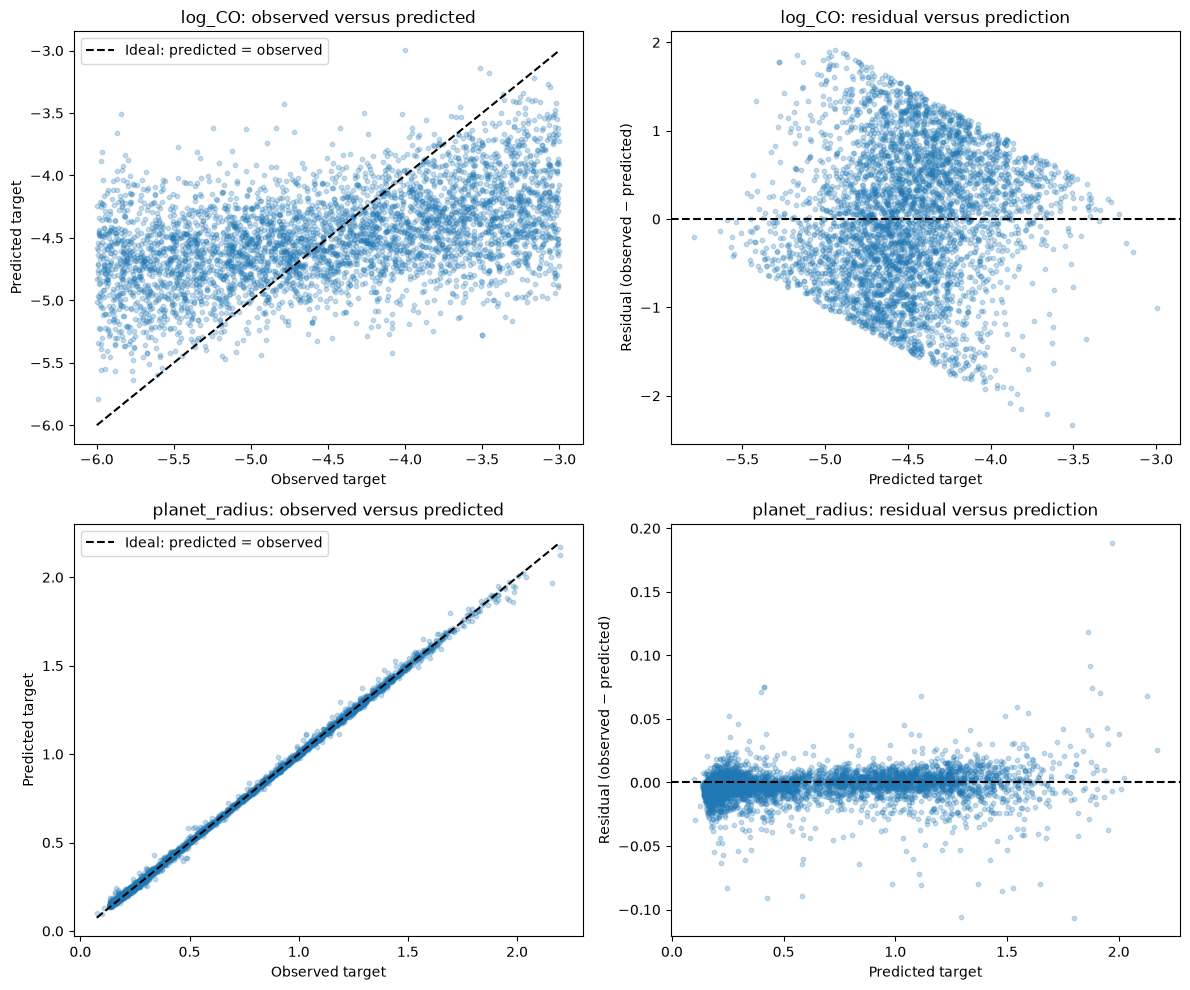

Displayed the targets with the lowest and highest selected-model validation R².


In [40]:
diagnostic_ranking = (
    validation_residuals_summary
    .sort_values(
        "selected_validation_R2",
        kind="stable",
    )
)

diagnostic_targets = list(
    dict.fromkeys(
        [
            diagnostic_ranking.iloc[0]["target"],
            diagnostic_ranking.iloc[-1]["target"],
        ]
    )
)

fig, axes = plt.subplots(
    nrows=len(diagnostic_targets),
    ncols=2,
    figsize=(12, 5 * len(diagnostic_targets)),
    squeeze=False,
)

for row_index, target in enumerate(
    diagnostic_targets
):
    observed = y_val[target].to_numpy(
        dtype=np.float64
    )

    predicted = selected_validation_predictions[
        target
    ]

    residual = observed - predicted

    observed_axis = axes[row_index, 0]
    residual_axis = axes[row_index, 1]

    observed_axis.scatter(
        observed,
        predicted,
        s=10,
        alpha=0.25,
        rasterized=True,
    )

    common_minimum = min(
        observed.min(),
        predicted.min(),
    )

    common_maximum = max(
        observed.max(),
        predicted.max(),
    )

    observed_axis.plot(
        [common_minimum, common_maximum],
        [common_minimum, common_maximum],
        linestyle="--",
        color="black",
        label="Ideal: predicted = observed",
    )

    observed_axis.set_title(
        f"{target}: observed versus predicted"
    )
    observed_axis.set_xlabel("Observed target")
    observed_axis.set_ylabel("Predicted target")
    observed_axis.legend()

    residual_axis.scatter(
        predicted,
        residual,
        s=10,
        alpha=0.25,
        rasterized=True,
    )

    residual_axis.axhline(
        0.0,
        linestyle="--",
        color="black",
    )

    residual_axis.set_title(
        f"{target}: residual versus prediction"
    )
    residual_axis.set_xlabel("Predicted target")
    residual_axis.set_ylabel(
        "Residual (observed − predicted)"
    )

plt.tight_layout()
plt.show()

print(
    "Displayed the targets with the lowest and highest "
    "selected-model validation R²."
)

In [41]:
selected_family_counts = (
    selected_model_summary[
        "selected_model_family"
    ]
    .value_counts()
    .rename_axis("model_family")
    .to_frame("n_targets")
)

highest_r2_row = validation_residuals_summary.loc[
    validation_residuals_summary[
        "selected_validation_R2"
    ].idxmax()
]

lowest_r2_row = validation_residuals_summary.loc[
    validation_residuals_summary[
        "selected_validation_R2"
    ].idxmin()
]

display(selected_family_counts)

print(
    "Highest selected-model validation R²:",
    highest_r2_row["target"],
    highest_r2_row["selected_validation_R2"],
)

print(
    "Lowest selected-model validation R²:",
    lowest_r2_row["target"],
    lowest_r2_row["selected_validation_R2"],
)

print("Calibration metrics calculated:", False)
print("Internal-test metrics calculated:", False)
print("Conformal intervals constructed:", False)

,n_targets
model_family,
NN,5
HGB,2


Highest selected-model validation R²: planet_radius 0.9991927695532078
Lowest selected-model validation R²: log_CO 0.23045443621344008
Calibration metrics calculated: False
Internal-test metrics calculated: False
Conformal intervals constructed: False
